# From notebook to product: Churn Radar

This notebook is the **index** for the repo. It walks through the worked example from the *Capstone · Deployment* deck:
a churn model, built as a **product for a retention manager** rather than a form with a Predict button.

| Step | What happens here | Where it lives in the app |
|---|---|---|
| 1 | Define the user & decision | `pages/about.py` |
| 2 | Load a **public** dataset (IBM Telco Customer Churn) | `src/features.py · DATA_URL` |
| 3 | Clean & explore | `src/features.py · clean()` |
| 4 | One feature pipeline, shared by training and the app | `src/features.py · build_pipeline()` |
| 5 | Train & evaluate | → `models/churn_v1.joblib` |
| 6 | Explain each prediction in plain words | `src/model.py · contributions()` |
| 7 | Save the model bundle and a sample file for “Try it” | `models/`, `data/sample.csv` |
| 8 | Smoke-test exactly what the app will run | `pages/predict.py` |
| 9 | Ship it to Streamlit Community Cloud | `README.md` |

> **No notebooks in the app.** Everything reusable is in `src/` as plain functions. The notebook only *calls* them, so the app prepares data exactly as training did.


## 1. Think product first

- **User:** a retention manager at a telecom provider.
- **Job:** every month, decide which customers the call team should phone first.
- **Decision:** who goes on the call list, and what offer to make (contract upgrade, discount, free tech support).

So the app's output is not `Churn: 1` — it's a **ranked, explained, downloadable call list** with a what-if for offers.


In [1]:
import sys, datetime as dt
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.metrics import (roc_auc_score, precision_score, recall_score,
                             classification_report, RocCurveDisplay)
from sklearn.model_selection import train_test_split

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))          # so `import src...` works from the notebook

from src.features import DATA_URL, ID_COL, TARGET, FEATURES, clean, prepare, build_pipeline
from src import model as m

pd.set_option("display.max_columns", 30)
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## 2. Load the public data

[IBM Telco Customer Churn](https://github.com/IBM/telco-customer-churn-on-icp4d): 7,043 customers of a fictional telecom provider,
with their services, account details, and whether they left in the last month (`Churn`). It's downloaded once and cached in `data/raw/` (git-ignored).


In [2]:
raw_path = ROOT / "data" / "raw" / "telco_churn.csv"
if not raw_path.exists():
    raw_path.parent.mkdir(parents=True, exist_ok=True)
    pd.read_csv(DATA_URL).to_csv(raw_path, index=False)

raw = pd.read_csv(raw_path)
print(raw.shape)
raw.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Clean & explore

Two quirks in the raw file, both handled in `clean()` so the app gets the same fix:
- `TotalCharges` is text, blank for brand-new customers (tenure 0) → numeric, blanks = 0.
- `SeniorCitizen` is 0/1 while every other flag is Yes/No → Yes/No.


In [3]:
print("Blank TotalCharges:", (raw["TotalCharges"].str.strip() == "").sum(),
      "| their tenure:", raw.loc[raw["TotalCharges"].str.strip() == "", "tenure"].unique())

df = clean(raw)
df[TARGET] = (df[TARGET] == "Yes").astype(int)
print(f"Churn rate: {df[TARGET].mean():.1%}")
df[FEATURES].describe(include="all").T[["count", "unique", "top", "mean"]]

Blank TotalCharges: 11 | their tenure: [0]
Churn rate: 26.5%


,count,unique,top,mean
tenure,7043.0,NaN,NaN,32.371149
MonthlyCharges,7043.0,NaN,NaN,64.761692
TotalCharges,7043.0,NaN,NaN,2279.734304
gender,7043,2,Male,NaN
SeniorCitizen,7043,2,No,NaN
Partner,7043,2,No,NaN
Dependents,7043,2,No,NaN
PhoneService,7043,2,Yes,NaN
MultipleLines,7043,3,No,NaN
InternetService,7043,3,Fiber optic,NaN


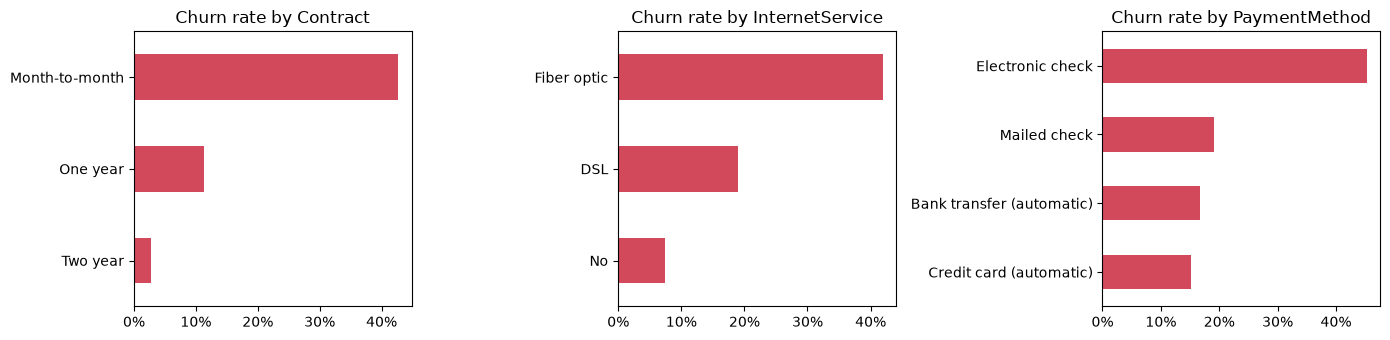

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    df.groupby(col)[TARGET].mean().sort_values().plot.barh(ax=ax, color="#d1495b")
    ax.set_title(f"Churn rate by {col}"); ax.set_xlabel(""); ax.set_ylabel("")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout()

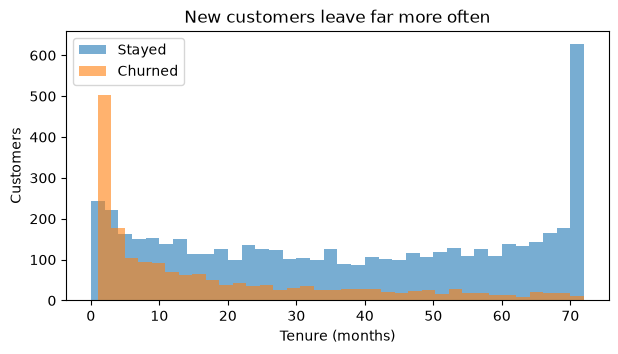

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for label, grp in df.groupby(TARGET):
    ax.hist(grp["tenure"], bins=36, alpha=.6, label="Churned" if label else "Stayed")
ax.set_xlabel("Tenure (months)"); ax.set_ylabel("Customers"); ax.legend()
ax.set_title("New customers leave far more often");

**Takeaways a retention manager cares about:** month-to-month contracts, fibre-optic internet, electronic-check payment and the first year of tenure carry the most risk. These should show up as the model's reasons too.

## 4–5. One pipeline: train & evaluate

`build_pipeline()` bundles scaling + one-hot encoding + a logistic regression in a single scikit-learn `Pipeline`.
Logistic regression is a deliberate product choice: its explanations are **exact** and easy to say in plain words.
We hold out 20% of customers as a test set.


In [6]:
X, y = prepare(df), df[TARGET]
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, df[ID_COL], test_size=0.2, stratify=y, random_state=42)

pipe = build_pipeline().fit(X_train, y_train)
proba = pipe.predict_proba(X_test)[:, 1]

THRESHOLD = 0.6   # default call-list threshold used in the app
pred = (proba >= THRESHOLD).astype(int)
metrics = {
    "roc_auc": roc_auc_score(y_test, proba),
    "precision": precision_score(y_test, pred),
    "recall": recall_score(y_test, pred),
    "threshold": THRESHOLD,
    "n_test": int(len(y_test)),
}
print({k: round(v, 3) for k, v in metrics.items()})
print(classification_report(y_test, pred, target_names=["stay", "churn"]))

{'roc_auc': 0.842, 'precision': 0.54, 'recall': 0.706, 'threshold': 0.6, 'n_test': 1409}
              precision    recall  f1-score   support

        stay       0.88      0.78      0.83      1035
       churn       0.54      0.71      0.61       374

    accuracy                           0.76      1409
   macro avg       0.71      0.74      0.72      1409
weighted avg       0.79      0.76      0.77      1409



Calling the riskiest 30% reaches 65% of churners.


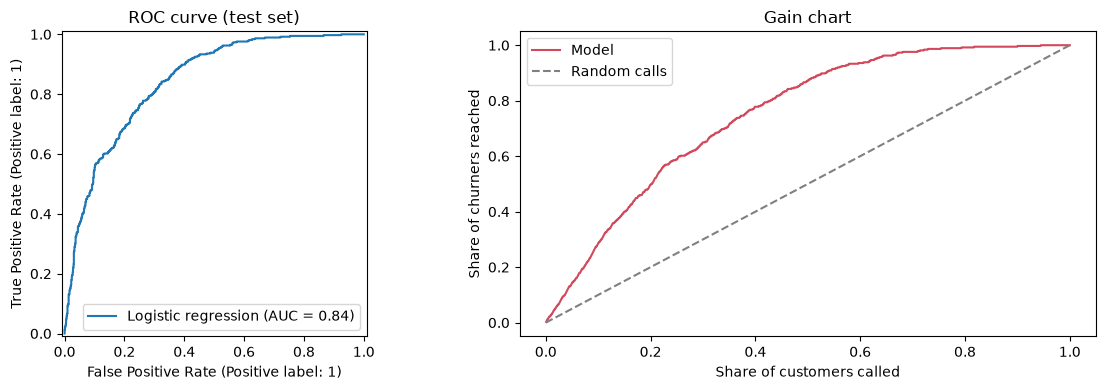

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
RocCurveDisplay.from_predictions(y_test, proba, ax=axes[0], name="Logistic regression")
axes[0].set_title("ROC curve (test set)")

# What a manager actually asks: if we call the top X% riskiest, how many churners do we reach?
order = np.argsort(-proba)
captured = np.cumsum(y_test.to_numpy()[order]) / y_test.sum()
share = np.arange(1, len(order) + 1) / len(order)
axes[1].plot(share, captured, color="#d1495b", label="Model")
axes[1].plot([0, 1], [0, 1], "--", color="grey", label="Random calls")
axes[1].set_xlabel("Share of customers called"); axes[1].set_ylabel("Share of churners reached")
axes[1].set_title("Gain chart"); axes[1].legend()
plt.tight_layout()
print(f"Calling the riskiest 30% reaches {captured[int(.3 * len(order))]:.0%} of churners.")

## 6. Explain each prediction

For a logistic regression, each feature's push on the log-odds is exactly `coef × (value − average)`.
`src/model.py · contributions()` computes this and sums the one-hot columns back to the original feature,
so the app can say *“Contract: Month-to-month”* instead of `cat__Contract_Month-to-month`.

The **baseline** (average transformed training row) is saved with the model so the app compares against the same “average customer”.


In [8]:
baseline = pipe.named_steps["prep"].transform(X_train).mean(axis=0)

bundle = {
    "pipeline": pipe,
    "baseline": baseline,
    "meta": {
        "version": "churn_v1",
        "trained_on": dt.date.today().isoformat(),
        "sklearn": sklearn.__version__,
        "data_url": "https://github.com/IBM/telco-customer-churn-on-icp4d",
        "n_rows": int(len(df)),
        "metrics": metrics,
    },
}

test_df = df.loc[X_test.index]
contrib = m.contributions(bundle, test_df)

# Sanity check: baseline log-odds + contributions must reproduce the model's own log-odds.
clf = pipe.named_steps["clf"]
recon = clf.intercept_[0] + baseline @ clf.coef_[0] + contrib.sum(axis=1)
assert np.allclose(recon, pipe.decision_function(X_test)), "explanations don't add up"

riskiest = test_df.assign(risk=proba).sort_values("risk", ascending=False).head(3)
for i, row in riskiest.iterrows():
    print(f"{row[ID_COL]}  risk {row['risk']:.0%}  ->  " + " | ".join(m.top_reasons(bundle, row, contrib.loc[i])))

5178-LMXOP  risk 94%  ->  Months as a customer: 1 | Internet service: Fiber optic | Contract: Month-to-month
0295-PPHDO  risk 93%  ->  Months as a customer: 1 | Internet service: Fiber optic | Contract: Month-to-month
6861-XWTWQ  risk 93%  ->  Months as a customer: 7 | Internet service: Fiber optic | Contract: Month-to-month


**Which levers can the app's what-if offer?** Only ones the model can separate from everything else.
The coefficient on `MonthlyCharges` is *negative* once the services are in the model: a bigger bill mostly means *more services*
(fibre, streaming), which are already counted. So the model can't tell us what a price discount would do, and the app
doesn't offer one. Contract length, tech support, online security and auto-pay are offered instead.


In [9]:
coefs = pd.Series(pipe.named_steps["clf"].coef_[0], pipe.named_steps["prep"].get_feature_names_out())
coefs.loc[["num__MonthlyCharges", "cat__Contract_Two year", "cat__TechSupport_Yes",
           "cat__OnlineSecurity_Yes", "cat__PaymentMethod_Credit card (automatic)"]].round(2)

num__MonthlyCharges                          -0.68
cat__Contract_Two year                       -0.77
cat__TechSupport_Yes                         -0.07
cat__OnlineSecurity_Yes                      -0.11
cat__PaymentMethod_Credit card (automatic)   -0.16
dtype: float64

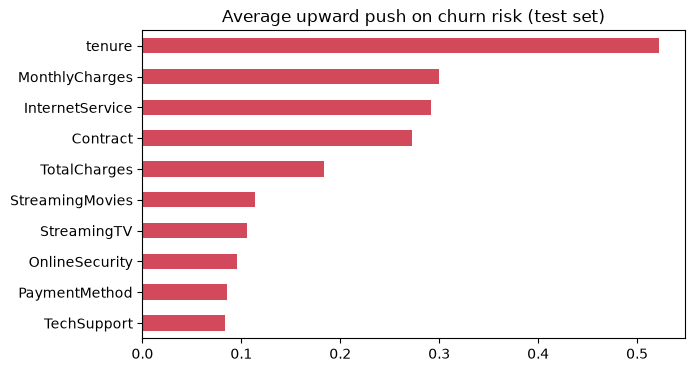

In [10]:
(contrib.clip(lower=0).mean().sort_values().tail(10)
   .plot.barh(color="#d1495b", figsize=(7, 4), title="Average upward push on churn risk (test set)"));

## 7. Save the model bundle and the “Try it” sample

- `models/churn_v1.joblib` — pipeline + baseline + metadata (version, date, metrics) shown on the About page.
- `data/sample.csv` — 300 **test-set** customers *without* the `Churn` label: what a manager would upload. Powers the “Try with sample data” button.


In [11]:
m.MODEL_PATH.parent.mkdir(exist_ok=True)
joblib.dump(bundle, m.MODEL_PATH, compress=3)

sample = raw.set_index(ID_COL).loc[id_test].reset_index().drop(columns=[TARGET]).sample(300, random_state=7)
sample.to_csv(m.SAMPLE_PATH, index=False)

print(m.MODEL_PATH.relative_to(ROOT), f"{m.MODEL_PATH.stat().st_size / 1024:.0f} KB")
print(m.SAMPLE_PATH.relative_to(ROOT), sample.shape)

models/churn_v1.joblib 3 KB
data/sample.csv (300, 20)


## 8. Smoke-test what the app will run

Reload from disk (as the deployed app will) and run the same calls `pages/predict.py` makes.


In [12]:
from src.features import validate

loaded = m.load_model()
s = pd.read_csv(m.SAMPLE_PATH)
assert validate(s) == [], validate(s)
s["risk"] = m.predict_risk(loaded, s)
c = m.contributions(loaded, s)
s["top_reason"] = [m.top_reasons(loaded, s.loc[i], c.loc[i], 1)[0] for i in s.index]

# Bad input gets a helpful message, not a crash
print(validate(s.drop(columns=["Contract", "tenure"])))

s.sort_values("risk", ascending=False)[["customerID", "risk", "top_reason", "Contract", "tenure", "MonthlyCharges"]].head(10)

['Missing columns: tenure, Contract']


,customerID,risk,top_reason,Contract,tenure,MonthlyCharges
161,1400-MMYXY,0.920128,Months as a customer: 3,Month-to-month,3,105.90
56,4750-ZRXIU,0.915064,Months as a customer: 4,Month-to-month,4,84.60
69,2034-GDRCN,0.903798,Months as a customer: 2,Month-to-month,2,90.40
115,4587-VVTOX,0.898253,Months as a customer: 6,Month-to-month,6,105.30
105,6969-MVBAI,0.896109,Months as a customer: 9,Month-to-month,9,90.10
155,2077-MPJQO,0.887194,Months as a customer: 7,Month-to-month,7,75.40
284,6979-ZNSFF,0.885153,Months as a customer: 8,Month-to-month,8,87.05
37,2027-FECZV,0.883829,Months as a customer: 12,Month-to-month,12,106.70
79,7817-BOQPW,0.882188,Months as a customer: 2,Month-to-month,2,75.55
17,2609-IAICY,0.881347,Months as a customer: 1,Month-to-month,1,77.15


In [13]:
# What-if: offer the riskiest customer a two-year contract plus free tech support
top = s.sort_values("risk", ascending=False).head(1).copy()
offer = top.assign(Contract="Two year", TechSupport="Yes")
print(f"Risk now {top['risk'].iloc[0]:.0%}  ->  with offer {m.predict_risk(loaded, offer)[0]:.0%}")

Risk now 92%  ->  with offer 68%


## 9. Ship it

```bash
pip install -r requirements.txt
streamlit run app.py          # local check at http://localhost:8501
```

**Streamlit Community Cloud in five steps**
1. **Pin versions** — `requirements.txt` pins the exact versions this model was trained with (scikit-learn especially).
2. **Push to GitHub** — code, `models/churn_v1.joblib` and `data/sample.csv` (both small, well under 100 MB).
3. **Connect** — sign in at [share.streamlit.io](https://share.streamlit.io), pick repo, branch and `app.py`.
4. **Add secrets** — none needed here; if you add one, paste it in the app's *Secrets* settings and read it with `st.secrets`.
5. **Share, iterate** — every `git push` redeploys. Check the logs when something breaks.

### Definition of done
- [ ] It has a live URL that works on a phone
- [x] Results are explained, not just a number
- [x] A stranger understands it in 10 seconds
- [x] Users can act: download, share or compare
- [x] There is a one-click example to try
- [x] Bad input gets a helpful message, not a crash
- [x] Versions are pinned and no secrets are in the repo
- [ ] Someone outside your team has tested it
